11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 2s 0us/step
Форма данных после предобработки: (60000, 28, 28, 1)


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)



Начало обучения модели...
Epoch 1/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.8943 - loss: 0.3442 - val_accuracy: 0.9759 - val_loss: 0.0738
Epoch 2/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9606 - loss: 0.1325 - val_accuracy: 0.9828 - val_loss: 0.0510
Epoch 3/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9703 - loss: 0.1025 - val_accuracy: 0.9862 - val_loss: 0.0422
Epoch 4/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9759 - loss: 0.0814 - val_accuracy: 0.9885 - val_loss: 0.0357
Epoch 5/5
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9790 - loss: 0.0675 - val_accuracy: 0.9899 - val_loss: 0.0319
313/313 - 2s - 6ms/step - accuracy: 0.9899 - loss: 0.0319

Точность модели на тестовых данных: 98.99%
1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 652ms/step


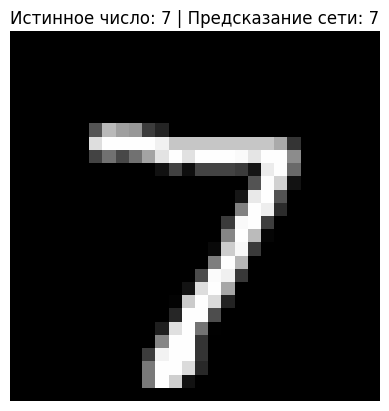

In [ ]:
import tensorflow as tf
import matplotlib.pyplot as plt
import numpy as np

# 1. ЗАГРУЗКА ДАННЫХ
# Загружаем датасет MNIST. Он сразу разделен на обучающую (60000) и тестовую (10000) выборки.
mnist = tf.keras.datasets.mnist
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. ПРЕДОБРАБОТКА ИЗОБРАЖЕНИЙ
# Нейронные сети лучше работают с небольшими значениями.
# Пиксели имеют значения от 0 до 255, поэтому мы нормализуем их к диапазону [0, 1].
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0

# Сверточные слои (Conv2D) ожидают данные в формате: (количество_образов, высота, ширина, каналы).
# Так как изображения черно-белые, у них 1 канал. Добавляем его с помощью reshape.
x_train = np.expand_dims(x_train, axis=-1)
x_test = np.expand_dims(x_test, axis=-1)

print(f"Форма данных после предобработки: {x_train.shape}")
# Ожидается: (60000, 28, 28, 1)

# 3. СОЗДАНИЕ НЕЙРОННОЙ СЕТИ (CNN)
model = tf.keras.models.Sequential([
    # Первый сверточный слой (извлекает простые признаки: линии, углы)
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu', input_shape=(28, 28, 1)),
    tf.keras.layers.MaxPooling2D((2, 2)), # Уменьшаем размерность в 2 раза

    # Второй сверточный слой (извлекает более сложные признаки)
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),

    # Преобразуем 2D матрицу в 1D вектор для подачи в полносвязные слои
    tf.keras.layers.Flatten(),

    # Полносвязный слой для классификации
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.5), # Отключаем 50% нейронов при обучении для защиты от переобучения

    # Выходной слой: 10 нейронов (по одному на каждую цифру от 0 до 9)
    # softmax преобразует выходы в вероятности (сумма вероятностей = 1)
    tf.keras.layers.Dense(10, activation='softmax')
])

# 4. КОМПИЛЯЦИЯ МОДЕЛИ
model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy', # Функция потерь для целочисленных меток
              metrics=['accuracy'])

# 5. ОБУЧЕНИЕ МОДЕЛИ
print("\nНачало обучения модели...")
history = model.fit(x_train, y_train,
                    epochs=5, # Проходов по всему датасету
                    batch_size=64,
                    validation_data=(x_test, y_test)) # Проверка точности на тестовых данных после каждой эпохи

# 6. ОЦЕНКА РЕЗУЛЬТАТОВ
test_loss, test_acc = model.evaluate(x_test, y_test, verbose=2)
print(f"\nТочность модели на тестовых данных: {test_acc*100:.2f}%")

# 7. ДЕМО: ПРЕДСКАЗАНИЕ НА СЛУЧАЙНОМ ИЗОБРАЖЕНИИ
# Берем первое изображение из тестовой выборки
image_index = 0
test_image = x_test[image_index]
true_label = y_test[image_index]

# Модель ожидает батч, поэтому добавляем измерение батча (1, 28, 28, 1)
test_image_batch = np.expand_dims(test_image, axis=0)

# Получаем предсказание
predictions = model.predict(test_image_batch)
predicted_label = np.argmax(predictions[0])

# Визуализация
plt.imshow(test_image.reshape(28, 28), cmap='gray')
plt.title(f"Истинное число: {true_label} | Предсказание сети: {predicted_label}")
plt.axis('off')
plt.show()